# CodeNova Task 1 — Sales Data Analysis

This notebook contains the dedicated Task 1 cells extracted from the original internship notebook.
It loads the Online Retail dataset, analyses quarterly/seasonal revenue, top products, country-wise sales, key metrics, charts, and creates a README.

**Dataset requirement:** Upload `online+retail.zip` when the upload cell runs, or update the file path if your dataset is already available in Colab.

In [12]:
import zipfile
import os

zip_name = "online+retail.zip"

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/online_retail")

print("ZIP extracted successfully!")
print(os.listdir("/content/online_retail"))

ZIP extracted successfully!
['Online Retail.xlsx']


In [13]:
import os

for root, folders, files_list in os.walk("/content/online_retail"):
    for name in files_list:
        print(os.path.join(root, name))

/content/online_retail/Online Retail.xlsx


In [14]:
import pandas as pd

file_path = "/content/online_retail/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())
print("First 5 rows:")
display(df.head())

Dataset loaded successfully!
Total rows: 541909
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [15]:
sales_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"], errors="coerce"
)
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Valid sales rows:", len(sales_df))
print("First date:", sales_df["InvoiceDate"].min())
print("Last date:", sales_df["InvoiceDate"].max())

Valid sales rows: 530104
First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00


Quarterly Sales Revenue:


,Quarter,Revenue
0,2010Q4,823746.140
1,2011Q1,1932635.810
2,2011Q2,2070084.541
3,2011Q3,2536949.743
4,2011Q4,3303268.310


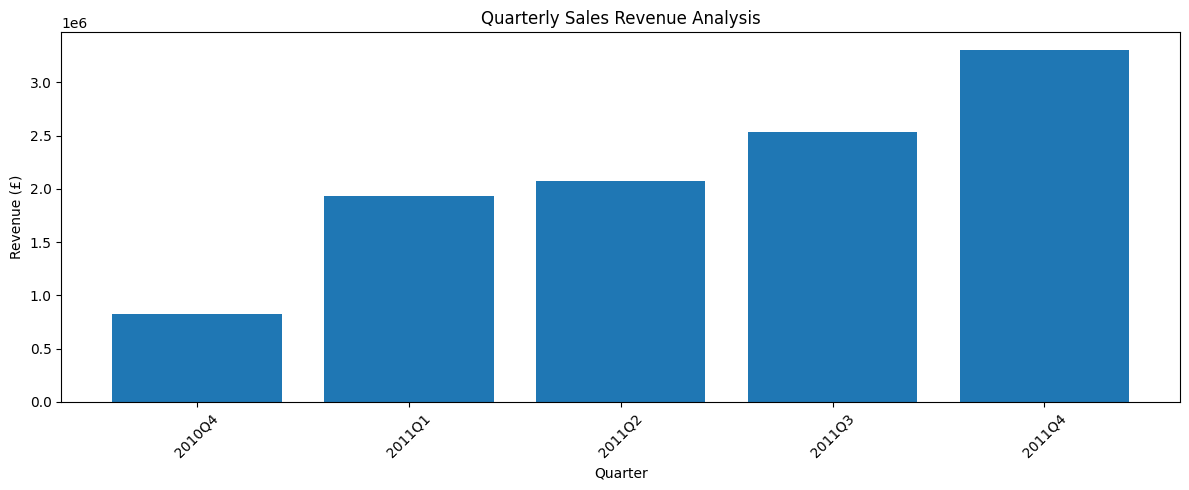

In [16]:
import matplotlib.pyplot as plt

# Extract quarter from invoice date
sales_df["Quarter"] = (
    sales_df["InvoiceDate"].dt.to_period("Q").astype(str)
)

# Calculate revenue for each quarter
quarterly_sales = (
    sales_df.groupby("Quarter")["Revenue"]
    .sum()
    .reset_index()
    .sort_values("Quarter")
)

print("Quarterly Sales Revenue:")
display(quarterly_sales)

# Plot chart
plt.figure(figsize=(12, 5))
plt.bar(quarterly_sales["Quarter"], quarterly_sales["Revenue"])
plt.title("Quarterly Sales Revenue Analysis")
plt.xlabel("Quarter")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Season,Revenue
0,Spring,2025984.001
1,Summer,2240099.471
2,Autumn,3723065.802
3,Winter,2677535.270


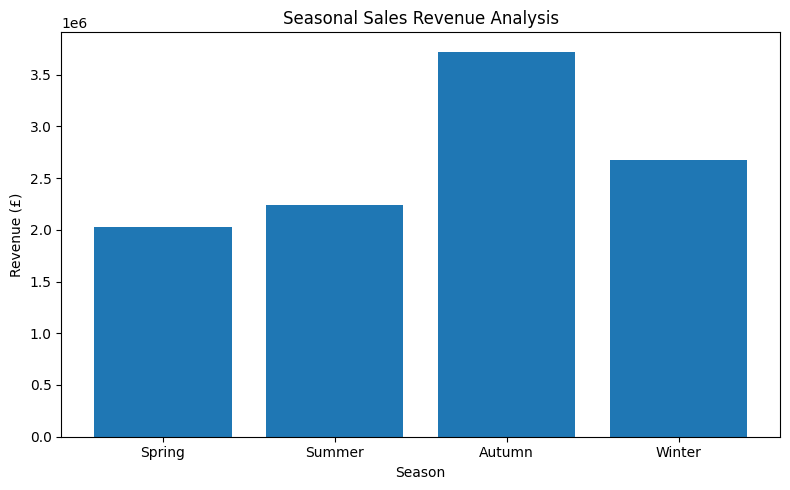

In [17]:
# Extract season from invoice month
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

sales_df["Season"] = sales_df["InvoiceDate"].dt.month.apply(get_season)

seasonal_sales = (
    sales_df.groupby("Season")["Revenue"]
    .sum()
    .reindex(["Spring", "Summer", "Autumn", "Winter"])
    .reset_index()
)

display(seasonal_sales)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(seasonal_sales["Season"], seasonal_sales["Revenue"])
plt.title("Seasonal Sales Revenue Analysis")
plt.xlabel("Season")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

,Description,Total_Revenue,Units_Sold
1067,DOTCOM POSTAGE,206248.77,706
2853,REGENCY CAKESTAND 3 TIER,174484.74,13879
2387,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3844,WHITE HANGING HEART T-LIGHT HOLDER,106292.77,37891
2413,PARTY BUNTING,99504.33,18295
1816,JUMBO BAG RED RETROSPOT,94340.05,48474
2052,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
2192,Manual,78112.82,7225
2692,POSTAGE,78101.88,3150
2741,RABBIT NIGHT LIGHT,66964.99,30788


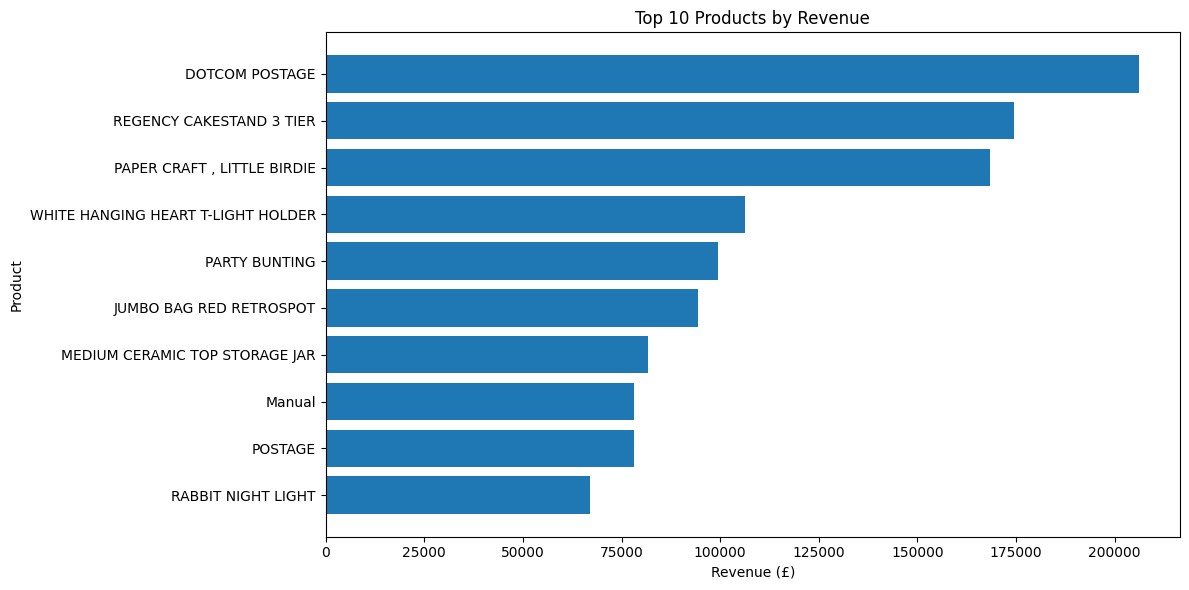

In [19]:
import matplotlib.pyplot as plt

# Find top 10 products by revenue
top_products = (
    sales_df.groupby("Description")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
)

display(top_products)

# Plot top 10 products
plt.figure(figsize=(12, 6))
plt.barh(
    top_products["Description"].astype(str).iloc[::-1],
    top_products["Total_Revenue"].iloc[::-1]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Top 10 Products by Quantity Sold:


,Description,Quantity
2387,"PAPER CRAFT , LITTLE BIRDIE",80995
2052,MEDIUM CERAMIC TOP STORAGE JAR,78033
3934,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
1816,JUMBO BAG RED RETROSPOT,48474
3844,WHITE HANGING HEART T-LIGHT HOLDER,37891
2681,POPCORN HOLDER,36761
227,ASSORTED COLOUR BIRD ORNAMENT,36461
2337,PACK OF 72 RETROSPOT CAKE CASES,36419
2741,RABBIT NIGHT LIGHT,30788
2107,MINI PAINT SET VINTAGE,26633


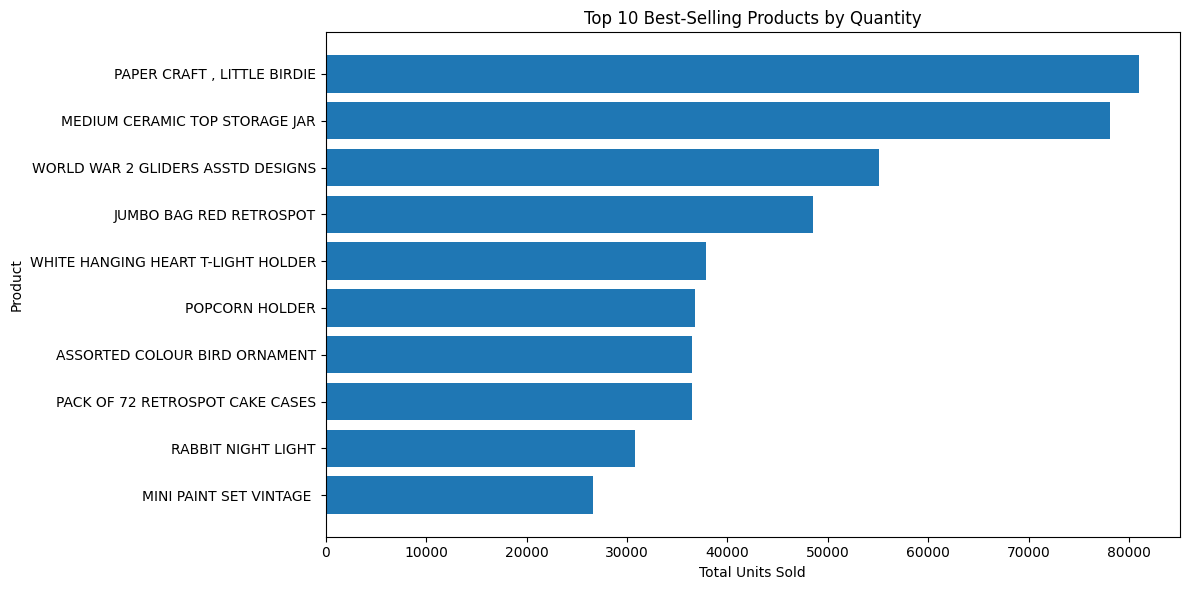

In [20]:
import matplotlib.pyplot as plt

# Find top 10 products by quantity sold
top_quantity = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .reset_index()
    .sort_values("Quantity", ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
display(top_quantity)

# Create chart
plt.figure(figsize=(12, 6))
plt.barh(
    top_quantity["Description"].astype(str).iloc[::-1],
    top_quantity["Quantity"].iloc[::-1]
)
plt.title("Top 10 Best-Selling Products by Quantity")
plt.xlabel("Total Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Top 10 Countries by Sales Revenue:


,Country,Revenue
0,United Kingdom,9025222.084
1,Netherlands,285446.340
2,EIRE,283453.960
3,Germany,228867.140
4,France,209715.110
5,Australia,138521.310
6,Spain,61577.110
7,Switzerland,57089.900
8,Belgium,41196.340
9,Sweden,38378.330


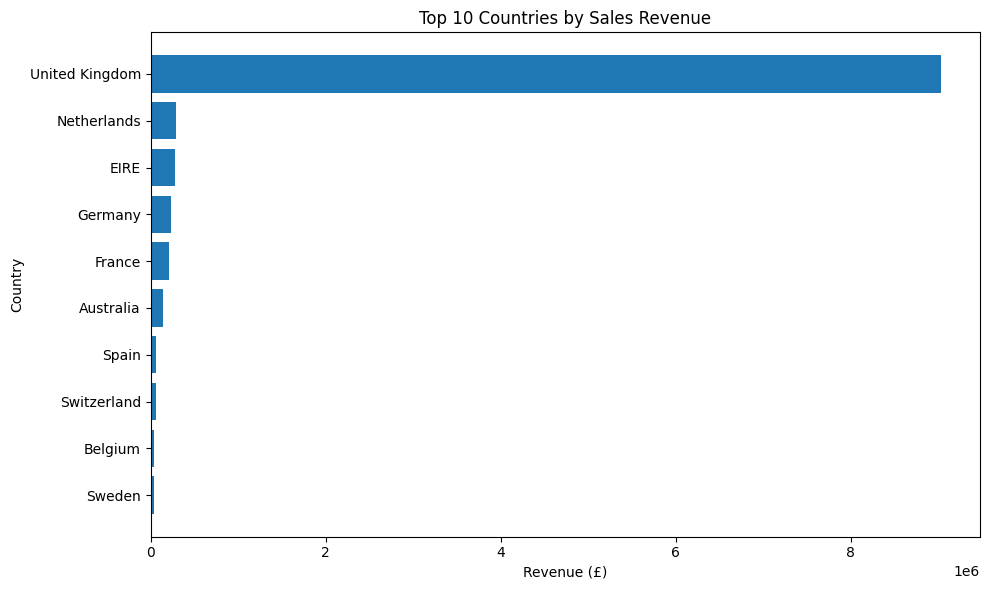

In [21]:
import matplotlib.pyplot as plt

# Calculate revenue by country
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 Countries by Sales Revenue:")
display(country_sales)

# Create chart
plt.figure(figsize=(10, 6))
plt.barh(
    country_sales["Country"].iloc[::-1],
    country_sales["Revenue"].iloc[::-1]
)
plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [22]:
# Calculate key business metrics
total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_quantity = sales_df["Quantity"].sum()
average_order_value = (
    total_revenue / total_orders if total_orders > 0 else 0
)
unique_products = sales_df["Description"].nunique()
unique_countries = sales_df["Country"].nunique()

print("===== SALES ANALYSIS KPI SUMMARY =====")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")
print(f"Unique Products: {unique_products:,}")
print(f"Countries Served: {unique_countries:,}")

===== SALES ANALYSIS KPI SUMMARY =====
Total Revenue: £10,666,684.54
Total Orders: 19,960
Total Quantity Sold: 5,588,376
Average Order Value: £534.40
Unique Products: 4,026
Countries Served: 38


In [23]:
# Identify the best quarter and country
best_quarter = quarterly_sales.loc[
    quarterly_sales["Revenue"].idxmax()
]

best_country = country_sales.loc[
    country_sales["Revenue"].idxmax()
]

best_product = top_products.loc[
    top_products["Total_Revenue"].idxmax()
]

print("===== BUSINESS INSIGHTS =====")
print(
    f"Highest revenue quarter: {best_quarter['Quarter']} "
    f"(£{best_quarter['Revenue']:,.2f})"
)
print(
    f"Top country by revenue: {best_country['Country']} "
    f"(£{best_country['Revenue']:,.2f})"
)
print(
    f"Top product by revenue: {best_product['Description']} "
    f"(£{best_product['Total_Revenue']:,.2f})"
)

print("\n===== RECOMMENDATIONS =====")
print("1. Plan inventory based on high-revenue periods.")
print("2. Study top-performing products and maintain sufficient stock.")
print("3. Focus marketing on high-revenue countries.")
print("4. Review low-performing periods and products for improvement.")

===== BUSINESS INSIGHTS =====
Highest revenue quarter: 2011Q4 (£3,303,268.31)
Top country by revenue: United Kingdom (£9,025,222.08)
Top product by revenue: DOTCOM POSTAGE (£206,248.77)

===== RECOMMENDATIONS =====
1. Plan inventory based on high-revenue periods.
2. Study top-performing products and maintain sufficient stock.
3. Focus marketing on high-revenue countries.
4. Review low-performing periods and products for improvement.


In [24]:
import os
import matplotlib.pyplot as plt

os.makedirs("Task1_Charts", exist_ok=True)

# Monthly sales chart
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"], monthly_sales["Revenue"], marker="o")
plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Task1_Charts/monthly_sales.png", dpi=300)
plt.close()

# Quarterly sales chart
plt.figure(figsize=(12, 5))
plt.bar(quarterly_sales["Quarter"], quarterly_sales["Revenue"])
plt.title("Quarterly Sales Revenue")
plt.xlabel("Quarter")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig("Task1_Charts/quarterly_sales.png", dpi=300)
plt.close()

# Top products by revenue
plt.figure(figsize=(12, 6))
plt.barh(
    top_products["Description"].astype(str).iloc[::-1],
    top_products["Total_Revenue"].iloc[::-1]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("Task1_Charts/top_products_revenue.png", dpi=300)
plt.close()

# Country sales
plt.figure(figsize=(10, 6))
plt.barh(
    country_sales["Country"].iloc[::-1],
    country_sales["Revenue"].iloc[::-1]
)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("Task1_Charts/country_sales.png", dpi=300)
plt.close()

print("All charts saved successfully!")
print(os.listdir("Task1_Charts"))

All charts saved successfully!
['quarterly_sales.png', 'monthly_sales.png', 'top_products_revenue.png', 'country_sales.png']


In [25]:
import shutil
from google.colab import files

shutil.make_archive("Task1_Charts", "zip", "Task1_Charts")
files.download("Task1_Charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
readme_content = """
# Task 1: Sales Data Analysis

## 1. Project Overview
This project analyses the Online Retail dataset to understand sales
performance, revenue trends, popular products, and country-wise sales.

## 2. Objectives
- Calculate total revenue, orders, quantity sold, and Average Order Value.
- Analyse monthly and quarterly revenue trends.
- Identify top-selling products by revenue and quantity.
- Compare sales revenue across countries.
- Provide data-driven business recommendations.

## 3. Dataset
Source: UCI Machine Learning Repository - Online Retail Dataset
https://archive.ics.uci.edu/dataset/352/online+retail

The dataset contains invoice details, product descriptions, quantities,
unit prices, invoice dates, customer IDs, and countries.

## 4. Data Preparation
- Converted invoice dates and numeric columns to appropriate data types.
- Excluded cancelled invoices identified by invoice numbers beginning with C.
- Excluded rows with non-positive quantities or unit prices.
- Calculated revenue as Quantity multiplied by UnitPrice.

## 5. Analysis Performed
- Key performance indicator (KPI) summary
- Monthly revenue trend
- Quarterly revenue trend
- Seasonal revenue analysis
- Top 10 products by revenue
- Top 10 products by quantity sold
- Top 10 countries by revenue

## 6. Business Recommendations
- Plan inventory using historical high-revenue periods.
- Maintain sufficient stock of products generating high revenue.
- Study high-performing markets to guide marketing decisions.
- Investigate low-performing periods and products for improvement.

## 7. Limitations
The dataset does not provide product cost information. Therefore,
actual profit and profit margins cannot be calculated reliably.
Revenue must not be interpreted as profit.

Seasonal patterns should be interpreted cautiously because the dataset
covers a limited historical period.

## 8. Tools Used
- Python
- Pandas
- Matplotlib
- Google Colab

## 9. Output Charts
The Task1_Charts folder contains the exported sales analysis charts.

## 10. Conclusion
The analysis provides an overview of retail sales performance and helps
identify revenue trends, popular products, and important markets.
Business decisions should be based on the calculated results and
the limitations of the available data.
"""

with open("README_Task1.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README_Task1.md created successfully!")

README_Task1.md created successfully!


In [27]:
from google.colab import files
files.download("README_Task1.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>